**Проект. Рассчет параметров A/B-теста с целью проверки гиротезы, результаты A/B-теста. Развлекательное приложение**
- Автор: Морозов Сергей Валентинович 


# Разработка A/B-тестирования и анализ результатов

Вы работаете продуктовым аналитиком в компании, которая разрабатывает развлекательное приложение с функцией «бесконечной» ленты, как, например, в приложениях с короткими видео. В вашем приложении существует две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя. Вас, как аналитика, просят помочь рассчитать параметры A/B-теста, который позволит проверить эту гипотезу, и проанализировать его результаты.

## Описание данных

Вы будете работать с тремя таблицами:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23. Путь к файлу: `/datasets/sessions_project_history.csv`.

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14. Путь к файлу: `/datasets/sessions_project_test_part.csv`.

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02. Путь к файлу: `/datasets/sessions_project_test.csv`.

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).


## Что нужно сделать
Ваши задачи: рассчитать параметры теста, оценить корректность его проведения и проанализировать результаты эксперимента.

### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest
from math import ceil

In [2]:
df_sessions_history = pd.read_csv('https://code.s3.yandex.net/datasets/sessions_project_history.csv')
df_sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


#### 1.2. Знакомство с данными
- Для каждого уникального пользователя `user_id` рассчитайте количество уникальных сессий `session_id`.

- Выведите на экран все данные из таблицы `sessions_history` для одного пользователя с наибольшим количеством сессий. Если таких пользователей несколько, выберите любого из них.

- Изучите таблицу для одного пользователя, чтобы лучше понять логику формирования каждого столбца данных.

In [3]:
# Список уникальных пользователей с количестов0м уникальных сессий, отсортированных по убыванию
user_id_list = df_sessions_history.groupby("user_id").session_id.nunique().sort_values(ascending = False)
user_id_list

user_id
10E0DEFC1ABDBBE0    10
6A73CB5566BB494D    10
8A60431A825D035B     9
D11541BAC141FB94     9
5BCFE7C4DCC148E9     9
                    ..
1DF13BB1953B3497     1
628502A3CE7E0A3C     1
1DEEF40DEFBD0C65     1
AC08479B7472C628     1
8A0882B6715D9EE5     1
Name: session_id, Length: 134039, dtype: int64

In [4]:
# Все данные по пользователю с максимальным  количестовом сессий
df_sessions_history[df_sessions_history['user_id'] == user_id_list.index[0]]

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


#### 1.3. Анализ числа регистраций
Одна из важнейших метрик продукта — число зарегистрированных пользователей. Используя исторические данные, визуализируйте, как менялось число регистраций в приложении за время его существования. Пользователь считается зарегистрированным только в день совершения регистрации. Таким образом, вам необходимо проанализировать количество зарегистрированных активных пользователей за каждый день без накопления (аналог DAU, но для регистраций пользователей).

- Агрегируйте исторические данные и рассчитайте число уникальных пользователей и число зарегистрированных пользователей для каждого дня наблюдения. Для простоты считайте, что у пользователя в течение дня бывает одна сессия максимум и статус регистрации в течение одного дня не может измениться.

- Постройте линейные графики общего числа пользователей и общего числа зарегистрированных пользователей по дням. Отобразите их на одном графике.

- Постройте отдельный линейный график доли зарегистрированных пользователей от всех пользователей по дням.

- На обоих графиках должны быть заголовок, подписанные оси X и Y, сетка и легенда.

In [5]:
# Количество зарегистрированных уникальных польователей по датам
df_reg_users = df_sessions_history[df_sessions_history['registration_flag']==1].groupby('session_date').agg({'user_id': 'nunique'}).copy()
df_reg_users = df_reg_users.rename(columns = {'user_id' : 'reg_users'})
df_reg_users.head()

,reg_users
session_date,
2025-08-11,169
2025-08-12,336
2025-08-13,464
2025-08-14,625
2025-08-15,840


In [6]:
# Количество уникальных пользователей(не обязательно зарегистрированных) по датам 
df_act_users = df_sessions_history.groupby('session_date').agg({'user_id': 'nunique'}).copy()
df_act_users = df_act_users.rename(columns = {'user_id' : 'act_users'})
df_act_users.head()

,act_users
session_date,
2025-08-11,3919
2025-08-12,6056
2025-08-13,8489
2025-08-14,10321
2025-08-15,14065


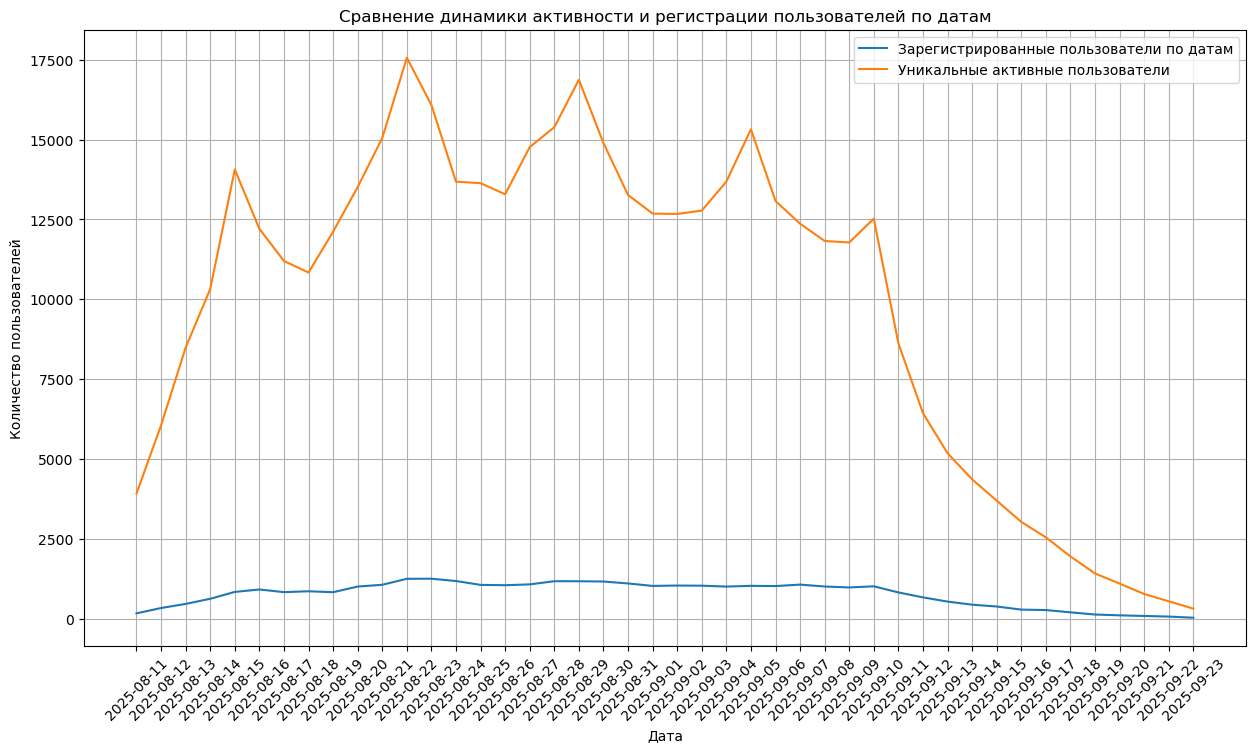

In [7]:
# Рисуем линейные графики.

plt.figure(figsize=(15, 8))
plt.plot(df_reg_users, label ='Зарегистрированные пользователи по датам')
plt.plot(df_act_users, label ='Уникальные активные пользователи')
plt.xlabel("Дата")
plt.ylabel("Количество пользователей")
plt.legend()
plt.title('Сравнение динамики активности и регистрации пользователей по датам')
plt.grid(True)
plt.xticks(rotation=45)
plt.show()


In [8]:
# Готовим данные для отдельного графика с долями
df_frac = pd.concat([df_reg_users, df_act_users], axis=1)
df_frac['fraction'] = df_frac['reg_users']/df_frac['act_users']
df_frac.head()

,reg_users,act_users,fraction
session_date,,,
2025-08-11,169,3919,0.043123
2025-08-12,336,6056,0.055482
2025-08-13,464,8489,0.054659
2025-08-14,625,10321,0.060556
2025-08-15,840,14065,0.059723


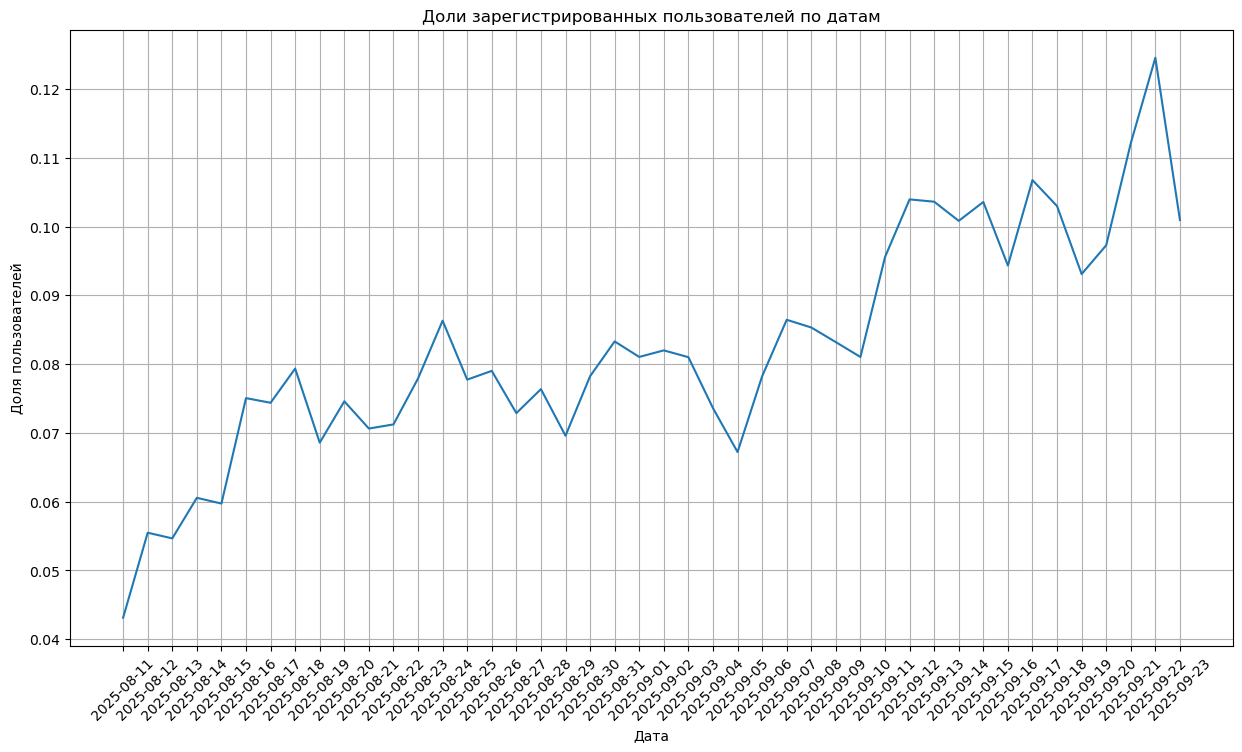

In [9]:
# Строим график доли зарегистрированных пользователей
plt.figure(figsize=(15, 8))
plt.plot(df_frac['fraction'])
plt.xlabel("Дата")
plt.ylabel("Доля пользователей")
#plt.legend()
plt.title('Доли зарегистрированных пользователей по датам')
plt.grid(True)
plt.xticks(rotation=45)
plt.show()


#### 1.4. Анализ числа просмотренных страниц
Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

В рамках задания проанализируйте число просмотренных страниц во время первых сессий пользователей. Найдите количество первых сессий для каждого значения количества просмотренных страниц. Например: одну страницу просмотрели в 8978 первых сессиях, две страницы — в 32 494 первых сессиях и так далее.

- Постройте столбчатую диаграмму, где по оси X будет число просмотренных страниц, по оси Y — количество сессий.

- На диаграмме должны быть заголовок, подписанные оси X и Y.

In [10]:
df_tmp = df_sessions_history[df_sessions_history['session_number'] == 1].groupby('page_counter').agg({'session_id' : 'count'})
df_tmp

,session_id
page_counter,
1,8978
2,32494
3,50939
4,32739
5,8075
6,777
7,37


<Figure size 1500x800 with 0 Axes>

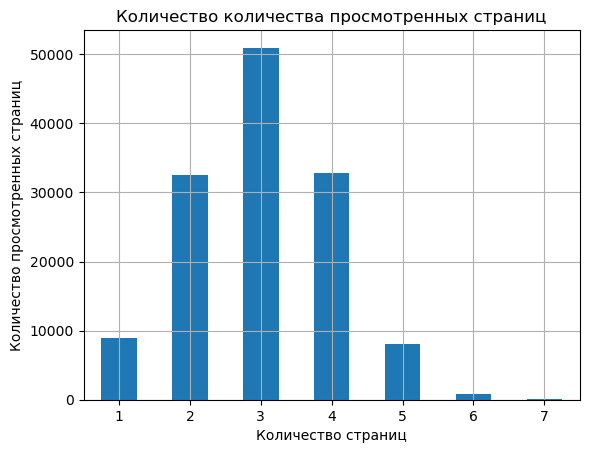

In [11]:
# Столбчатая диаграмма
plt.figure(figsize=(15, 8))
df_tmp.plot(kind = 'bar', rot = 0, legend = False)
plt.xlabel("Количество страниц")
plt.ylabel("Количество просмотренных страниц")
plt.title('Количество количества просмотренных страниц')
plt.grid(True)
plt.show()

#### 1.5. Доля пользователей, просмотревших более четырёх страниц
Продуктовая команда продукта считает, что первые сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель является важной прокси-метрикой для продукта.

- В датафрейме `sessions_history` создайте дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если было просмотрено меньше.

- Постройте график со средним значением доли успешных первых сессий от всех первых сессий пользователей. Данные нужно визуализировать по дням за весь период наблюдения.

In [12]:
# Создаем новый столбец
df_sessions_history['good_session'] = 0
# Обновим столбец по условию
df_sessions_history.loc[(df_sessions_history['session_number'] == 1)&(df_sessions_history['page_counter']>3), 'good_session'] = 1
# Визуаьно проверяем
df_sessions_history[['page_counter', 'good_session']].head()

,page_counter,good_session
0,3,0
1,4,1
2,4,1
3,4,1
4,3,0


In [13]:
# Строим график
# Сначала подготовим данные во временный датафрейм
df_tmp = df_sessions_history[df_sessions_history['session_number'] == 1].groupby('session_date').agg({'good_session' :'mean'})
df_tmp.head()

,good_session
session_date,
2025-08-11,0.312835
2025-08-12,0.298344
2025-08-13,0.306861
2025-08-14,0.319098
2025-08-15,0.311114


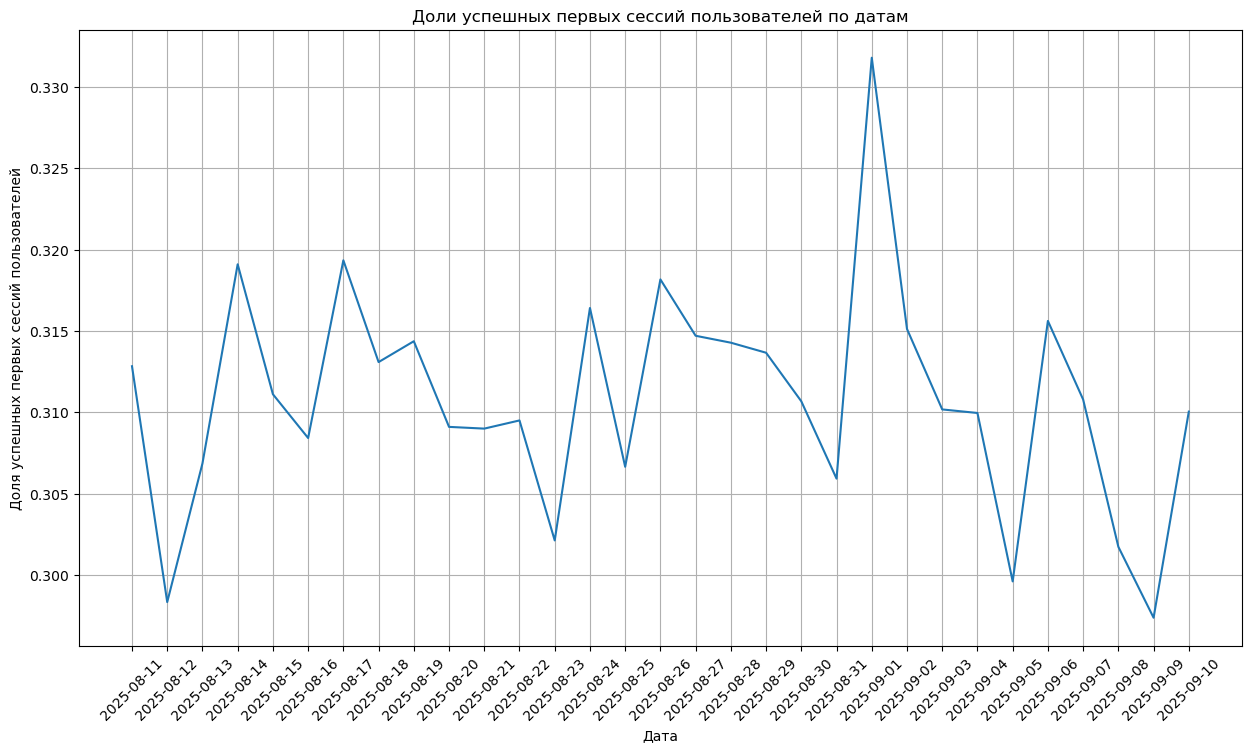

In [14]:
# Строим график
plt.figure(figsize=(15, 8))
plt.plot(df_tmp)
plt.xlabel("Дата")
plt.ylabel("Доля успешных первых сессий пользователей")
#plt.legend()
plt.title('Доли успешных первых сессий пользователей по датам')
plt.grid(True)
plt.xticks(rotation=45)
plt.show()


### 2. Подготовка к тесту
При планировании теста необходимо проделать несколько важных шагов:

- Определиться с целевой метрикой.

- Рассчитать необходимый размер выборки.

- Исходя из текущих значений трафика рассчитать необходимую длительность проведения теста.

#### 2.1. Расчёт размера выборки
В рамках курса вы уже рассчитывали размеры выборки и  использовали для этого онлайн-калькулятор. В этом задании предлагаем воспользоваться готовым кодом и рассчитать необходимое для вашего эксперимента количество пользователей.

Для этого установите в коде ниже следующие параметры:

- Уровень значимости — 0.05.

- Вероятность ошибки второго рода — 0.2.

- Мощность теста.

- Минимальный детектируемый эффект, или MDE, — 3%. Обратите внимание, что здесь нужно указать десятичную дробь, а не процент.

При расчёте размера выборки используйте метод `solve_power()` из класса `power.NormalIndPower` модуля `statsmodels.stats`.

Запустите ячейку и изучите полученное значение.

In [15]:
# Задайте параметры:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 1-beta  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = 0.03*p  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


#### 2.2. Расчёт длительности A/B-теста

Используйте данные о количестве пользователей в каждой выборке и среднем количестве пользователей приложения. Рассчитайте длительность теста, разделив одно на другое.

- Рассчитайте среднее количество уникальных пользователей приложения в день.

- Определите длительность теста исходя из рассчитанного значения размера выборок и среднего дневного трафика приложения. Количество дней округлите в большую сторону.

In [16]:
# Среднее количество пользователей приложения в день по историческим данным
avg_daily_users = df_sessions_history.groupby('session_date').user_id.nunique().mean()

# Рассчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = ceil(2*sample_size/avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровене трафика в {avg_daily_users} пользователей в день составит {test_duration} дней")

Рассчитанная длительность A/B-теста при текущем уровене трафика в 9907.363636363636 пользователей в день составит 9 дней


### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей

A/B-тест успешно запущен, и уже доступны данные за первые три дня. На этом этапе нужно убедиться, что всё идёт хорошо: пользователи разделены правильным образом, а интересующие вас метрики корректно считаются.

- Считайте и сохраните в датафрейм `sessions_test_part` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test_part.csv`.

- Рассчитайте количество уникальных пользователей в каждой из экспериментальных групп для одного дня наблюдения.

- Рассчитайте и выведите на экран процентную разницу в количестве пользователей в группах A и B. Постройте любую удобную визуализацию, на которой будет видно возможное различие двух групп.

Для расчёта процентной разницы воспользуйтесь формулой:
$$P = 100 \cdot  \frac{|A − B|}{A}$$

In [17]:
# Считываем данные в датафрейм и подготоавливаем данные
df_sessions_test_part = pd.read_csv('https://code.s3.yandex.net/datasets/sessions_project_test_part.csv')
n_a = df_sessions_test_part[df_sessions_test_part.test_group == 'A'].user_id.nunique()
n_b = df_sessions_test_part[df_sessions_test_part.test_group == 'B'].user_id.nunique()
print(f'Процентная разница в группах A и B равна: {round(100*abs(n_a-n_b)/n_a, 2)}')

Процентная разница в группах A и B равна: 0.74


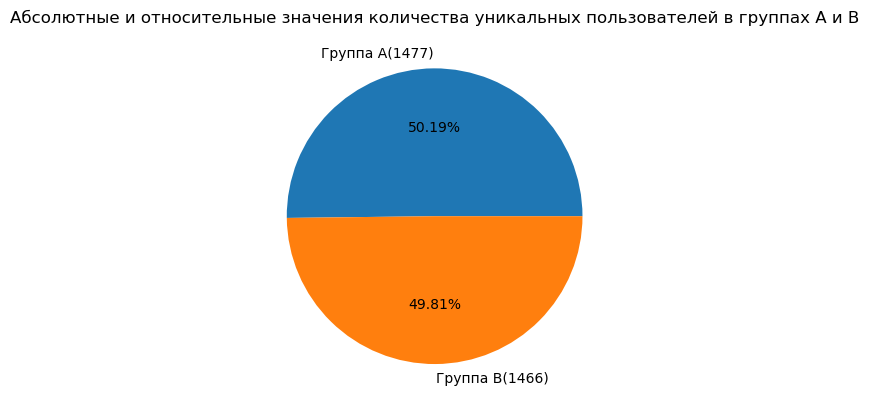

In [18]:
# Визуализация
pd.Series([n_a, n_b], index=[f'Группа A({str(n_a)})', f'Группа B({str(n_b)})']).plot(kind='pie', autopct='%1.2f%%')
plt.title('Абсолютные и относительные значения количества уникальных пользователей в группах A и B')
plt.show()

#### 3.2. Проверка пересечений пользователей
Помимо проверки равенства количества пользователей в группах, полезно убедиться в том, что группы независимы. Для этого нужно убедиться, что никто из пользователей случайно не попал в обе группы одновременно.

- Рассчитайте количество пользователей, которые встречаются одновременно в группах A и B, или убедитесь, что таких нет.

In [19]:
# Создаем массивы пользователей групп А и B
gr_a = df_sessions_test_part[df_sessions_test_part['test_group'] == 'A']['user_id']
gr_b = df_sessions_test_part[df_sessions_test_part['test_group'] == 'B']['user_id']
# Делаем пересечение массивов оставив в них только уникальных пользователей оператором set
intersection = list(set(gr_a) & set(gr_b))
print("Количество пользователей в обеих группах равно:", len(intersection))

Количество пользователей в обеих группах равно: 0


#### 3.3. Равномерность разделения пользователей по устройствам
Полезно также убедиться в том, что пользователи равномерно распределены по всем доступным категориальным переменным — типам устройств и регионам.

Постройте две диаграммы:

- доля каждого типа устройства для пользователей из группы A,

- доля каждого типа устройства для пользователей из группы B.

Постарайтесь добавить на диаграммы все необходимые подписи, пояснения и заголовки, которые позволят сделать вывод о том, совпадает ли распределение устройств в группах A и B.


In [20]:
# Подготовка данных для визуализации
df_a = df_sessions_test_part[df_sessions_test_part['test_group'] == 'A'].groupby('device').agg(device_a_count = ('user_id','nunique'))
#df_a = df_a.rename(columns = {'device':'device_a_count'})
df_a_sum = df_a.device_a_count.sum()
df_a['frac_a'] = round(100*df_a['device_a_count']/df_a_sum, 2)
df_b = df_sessions_test_part[df_sessions_test_part['test_group'] == 'B'].groupby('device').agg(device_b_count = ('user_id','nunique'))
#df_b = df_b.rename(columns = {'device':'device_b_count'})
df_b_sum = df_b.device_b_count.sum()
df_b['frac_b'] = round(100*df_b['device_b_count']/df_b_sum, 2)
df_frac_ab = pd.concat([df_a['frac_a'], df_b['frac_b']], axis=1)
df_frac_ab

,frac_a,frac_b
device,,
Android,44.41,45.57
Mac,10.56,10.10
PC,24.98,25.99
iPhone,20.04,18.35


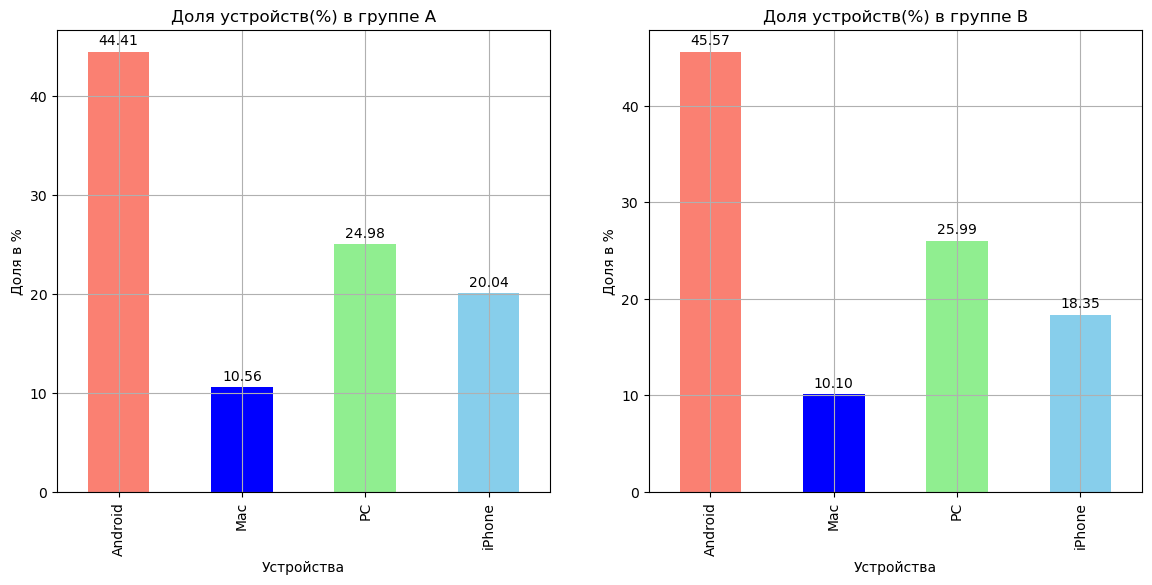

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

colors_list = ["salmon", "blue", "lightgreen", 'skyblue']
#device_type = ["Android", "Mac", "PC", 'iPhone']
df_frac_ab['frac_a'].plot(
    kind='bar', xlabel = 'Устройства', ylabel = 'Доля в %', 
    title = 'Доля устройств(%) в группе A',
    grid = True,
    color=colors_list,
    ax = ax[0]
)
for container in ax[0].containers:
    ax[0].bar_label(container, fmt='%.2f', padding=3)
df_frac_ab['frac_b'].plot(
    kind='bar', xlabel = 'Устройства', ylabel = 'Доля в %', 
    title = 'Доля устройств(%) в группе B',
    grid = True,
    color=colors_list,    
    ax = ax[1]
)
for container in ax[1].containers:
    ax[1].bar_label(container, fmt='%.2f', padding=3)

plt.show()

#### 3.4. Равномерность распределения пользователей по регионам
Теперь убедитесь, что пользователи равномерно распределены по регионам.

Постройте две диаграммы:

- доля каждого региона для пользователей из группы A,

- доля каждого региона для пользователей из группы B.

Постарайтесь добавить на диаграммы все необходимые подписи, пояснения и заголовки, которые позволят сделать вывод о том, совпадает ли распределение регионов в группах A и B. Постарайтесь использовать другой тип диаграммы, не тот, что в прошлом задании.

In [22]:
# Подготовка данных
df_a_reg = df_sessions_test_part[df_sessions_test_part['test_group'] == 'A'].groupby('region').agg({'user_id' : 'nunique'})
a_reg_sum = df_a_reg.user_id.sum()
df_a_reg['frac_a'] = round(100*df_a_reg['user_id']/a_reg_sum, 2)
df_b_reg = df_sessions_test_part[df_sessions_test_part['test_group'] == 'B'].groupby('region').agg({'user_id' : 'nunique'})
b_reg_sum = df_b_reg.user_id.sum()
df_b_reg['frac_b'] = round(100*df_b_reg['user_id']/b_reg_sum, 2)
df_frac_reg_ab = pd.concat([df_a_reg['frac_a'], df_b_reg['frac_b']], axis=1)
df_frac_reg_ab

,frac_a,frac_b
region,,
CIS,43.60,44.0
EU,15.17,14.8
MENA,41.23,41.2


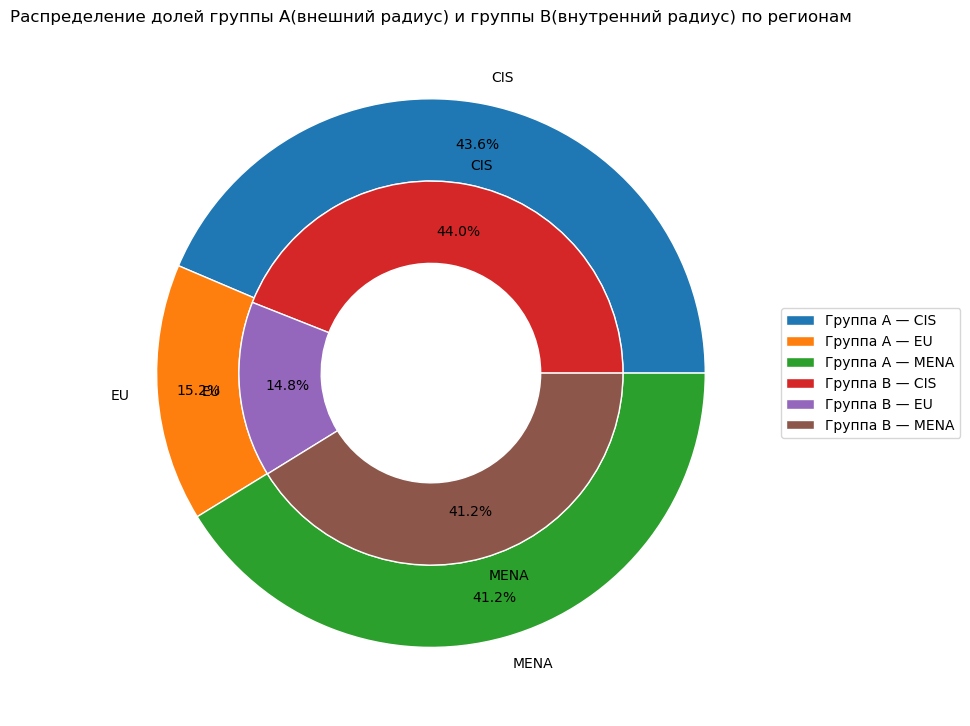

In [23]:
fig, ax = plt.subplots(figsize=(9, 9))

size = 0.3

# Внешнее кольцо
wedges_a, _, _ = ax.pie(
    df_frac_reg_ab['frac_a'], radius=1, autopct='%1.1f%%',
    pctdistance=0.85, wedgeprops=dict(width=size, edgecolor='w'),
    labels=df_frac_reg_ab.index
)

# Внутреннее кольцо
wedges_b, _, _ = ax.pie(
    df_frac_reg_ab['frac_b'], radius=1 - size, autopct='%1.1f%%',
    pctdistance=0.75, wedgeprops=dict(width=size, edgecolor='w'),
    labels=df_frac_reg_ab.index
)

# Легенда
legend_labels = [f'Группа A — {i}' for i in df_frac_reg_ab.index] + [f'Группа B — {i}' for i in df_frac_reg_ab.index]
ax.legend(wedges_a + wedges_b, legend_labels,
          loc='center left', bbox_to_anchor=(1, 0.5))

ax.set_title('Распределение долей группы А(внешний радиус) и группы B(внутренний радиус) по регионам')
plt.tight_layout()
plt.show()

#### 3.5. Вывод после проверки A/B-теста

На основе проведённого анализа A/B-теста сформулируйте и запишите свои выводы. В выводе обязательно укажите:

- Было ли обнаружено различие в количестве пользователей в двух группах.

- Являются ли выборки независимыми. Было ли обнаружено пересечение пользователей из тестовой и контрольной групп.

- Сохраняется ли равномерное распределение пользователей тестовой и контрольной групп по категориальным переменным: устройствам и регионам.

Сделайте заключение: корректно ли проходит A/B-тест, или наблюдаются какие-либо нарушения.

_Промежуточные выводы:_
- различия в количестве пользователей в двух группах незначительное (в группе А - 1477 пользователей, в группе В - 1466, а процентая разница между группами составляет 0,7%);
- выборки независимые (в тестовой и контрольной группах не выявлено пересечений по уникальным идентификаторам пользователей);
- распределение пользователей тестовой и контрольной групп по категориальным переменным: устройствам и регионам равномерное.

### 4. Проверка результатов A/B-теста

A/B-тест завершён, и у вас есть результаты за все дни проведения эксперимента. Необходимо убедиться в корректности теста и верно интерпретировать результаты.

#### 4.1. Получение результатов теста и подсчёт основной метрики

- Считайте и сохраните в датафрейм `sessions_test` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test.csv`.

- В датафрейме `sessions_test` создайте дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если просмотрено меньше.

In [24]:
df_sessions_test=pd.read_csv('https://code.s3.yandex.net/datasets/sessions_project_test.csv')

In [25]:
df_sessions_test['good_session'] = 0
df_sessions_test.loc[df_sessions_test['page_counter'] > 3, ['good_session']] = 1
#Визуально проверяем
df_sessions_test['good_session'].value_counts()

good_session
0    68698
1    31307
Name: count, dtype: int64

#### 4.2 Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик


Перед тем как проводить А/B-тест, необходимо сформулировать нулевую и альтернативную гипотезы. Напомним изначальное условие: команда разработчиков рекомендательных систем создала новый алгоритм, который, по их мнению, будет показывать более интересный контент для каждого пользователя.

Подумайте, о какой метрике идёт речь и как она будет учтена в формулировке гипотез. Сформулируйте нулевую и альтернативную гипотезы.

Не забывайте, что до проведения эксперимента важно выделять и отслеживать изменение прокси- и барьерных метрик. В имеющихся у вас данных о проведении эксперимента этих метрик нет. Подумайте, какие показатели вы бы выбрали в качестве прокси- и барьерных метрик, если бы проводили этот эксперимент самостоятельно.

 - _Нулевая гипотеза (Н0): Доли успешных первых сессий у пользователей в контрольной (группа А) и тестовой (группа В) групп равны._
- _Альтернативная гипотеза (Н1): Доля успешных первых сессий у пользователей, которые воспользовались новым алгоритном рекомендательных систем, выросла по сравнению с долей пользователей, которым не был предложен новый алгоритм (p_А < p_B)._

_В качестве **прокси-метрик** можно рассмотреть возможность: посчитать время, проведенное в приложении (но в таблице нет данных по длительности сессий); долю пользователей, взаимодействующих с новым блоком рекомендаций; долю пользователей, которые после просмотра контента, зарегистрировались в приложении (возможно новый интересный контент простимулирует пользователей зарегистрироваться, а в дальнейшем и купить подписку)._

_В качестве **барьерных метрик** можно предложить: увеличение доли отказов в приложении (чтобы оценить насколько новый контент притягивает/отталкивает пользователей); скорость загрузки страниц; активность пользователей (если активность падает, значит новый алгоритм не удовлетворяет потребностям/интересам пользователей)._


#### 4.3. Сравнение доли успешных первых сессий

Перейдем к анализу ключевой метрики — доле успешных первых сессий.

Используйте созданный на первом шаге задания столбец `good_session` и рассчитайте долю успешных первых сессий для выборок A и B, а также разницу в этом показателе. Полученный вывод отобразите на экране.

In [26]:
# Расчитываем доли
frac_a = df_sessions_test[(df_sessions_test['test_group'] == 'A')&(df_sessions_test['session_number']==1)].good_session.mean()
frac_b = df_sessions_test[(df_sessions_test['test_group'] == 'B')&(df_sessions_test['session_number']==1)].good_session.mean()
print(f'Доля успешных первых сессий для группы А равна: {round(frac_a, 5)}', f'Доля успешных первых сессий для группы B равна: {round(frac_b, 5)}', sep='\n')
print(f'Разница в долях равна: {round(abs(frac_a - frac_b), 5)}')

Доля успешных первых сессий для группы А равна: 0.31572
Доля успешных первых сессий для группы B равна: 0.31467
Разница в долях равна: 0.00105


_Промежуточный вывод: Разница в долях успешных первых сессий групп А и B составляет 0.1 %. Различие показателя в группах пренебрежительно мало._

#### 4.4. Насколько статистически значимо изменение ключевой метрики

На предыдущем шаге вы убедились, что доли успешных первых сессий в тестовой и контрольной выборках близки, но делать выводы только на основе этого значения будет некорректно. Для принятия решения всегда необходимо отвечать на вопрос: является ли это изменение статистически значимым.

- Используя статистический тест, рассчитайте, является ли изменение в метрике доли успешных первых сессий статистически значимым.

- Выведите на экран полученное значение p-value и свои выводы о статистической значимости. Напомним, что уровень значимости в эксперименте был выбран на уровне 0.05.

In [27]:
# Проводим Z-тест пропорций
n_a = df_sessions_test[(df_sessions_test.test_group=='A')& (df_sessions_test.session_number==1)].shape[0] # Посчитаем размер группы A
n_b = df_sessions_test[(df_sessions_test.test_group=='B')& (df_sessions_test.session_number==1)].shape[0] # Посчитаем размер группы В

m_a = df_sessions_test[(df_sessions_test.test_group=='A') & (df_sessions_test.session_number==1) & (df_sessions_test.good_session==1)
].shape[0] # Посчитаем кол-во успехов в группе A

m_b = df_sessions_test[(df_sessions_test.test_group=='B') & (df_sessions_test.session_number==1) & (df_sessions_test.good_session==1)
].shape[0] # Посчитаем кол-во успехов в группе В

p_a, p_b = m_a/n_a, m_b/n_b # Посчитаем доли успехов для каждой группы: A и B

if (p_a*n_a > 10) and ((1-p_a)*n_a > 10) and (p_b*n_b > 10)and((1-p_b)*n_b > 10): # Проверим предпосылку о достаточном количестве данных
    print('Предпосылка о достаточном количестве данных выполняется!')
else:
    print('Предпосылка о достаточном количестве данных НЕ выполняется!')

alpha = 0.05 # Установим уровень значимости

stat_ztest, p_value_ztest = proportions_ztest([m_a, m_b], # Проводим Z-тест пропорций
    [n_a, n_b],
    alternative='smaller' # так как H_1: p_a < p_b
)

print(f'pvalue={p_value_ztest}') # Выведем полученное p-value 

if p_value_ztest > alpha:
    print('Нулевая гипотеза подтверждается')
else:
    print('Нулевая гипотеза не подтверждается')
    
print(f'Доля успешных первых сессий у пользователей, которые воспользовались новым алгоритном рекомендательных систем не изменилась.')

Предпосылка о достаточном количестве данных выполняется!
pvalue=0.5783523649187868
Нулевая гипотеза подтверждается
Доля успешных первых сессий у пользователей, которые воспользовались новым алгоритном рекомендательных систем не изменилась.


#### 4.5. Вывод по результатам A/B-эксперимента

На основе проведённого анализа результатов теста сформулируйте и запишите свои выводы для команды разработки приложения. В выводе обязательно укажите:

- Характеристики проведённого эксперимента, количество задействованных пользователей и длительность эксперимента.

- Повлияло ли внедрение нового алгоритма рекомендаций на рост ключевой метрики и как.

- Каким получилось значение p-value для оценки статистической значимости выявленного эффекта.

- Стоит ли внедрять нововведение в приложение.

In [28]:
#Перед окончательым выводом возьмем некотрые данные из тестового набора
print(f'Длина тестового набора данных: {len(df_sessions_test)}')
print(f'Количество уникальных пользователей принадлежащих группе A: {df_sessions_test[df_sessions_test['test_group'] == 'A'].user_id.nunique()}')
print(f'Количество уникальных пользователей принадлежащих группе B: {df_sessions_test[df_sessions_test['test_group'] == 'B'].user_id.nunique()}')
print(f'Количество уникальных пользователей принадлежащих группе A в первой сессии: {df_sessions_test[(df_sessions_test['test_group'] == 'A')&(df_sessions_test.session_number==1)].user_id.nunique()}')
print(f'Количество уникальных пользователей принадлежащих группе B в первой сессии: {df_sessions_test[(df_sessions_test['test_group'] == 'B')&(df_sessions_test.session_number==1)].user_id.nunique()}')
print(f'Срок проведения тестирования: {df_sessions_test['session_date'].nunique()} дней')

Длина тестового набора данных: 100005
Количество уникальных пользователей принадлежащих группе A: 15163
Количество уникальных пользователей принадлежащих группе B: 15416
Количество уникальных пользователей принадлежащих группе A в первой сессии: 15162
Количество уникальных пользователей принадлежащих группе B в первой сессии: 15416
Срок проведения тестирования: 20 дней


_Вывод._  
_На основе произведенных расчетов получаем, что необходимый размер выборки для каждой группы составляет 41040 пользователей. Длительность теста составляет 9 дней при трафике 9907 пользователей в день.  
Однако, по факту(на основе тестового набора данных) количество уникальных пользователей значительно меньше(для гр. А 15162, для гр B 15416).
При этом реальная длительность тестирования составила 20 дней, что превышает расчетную длительность. Мощности теста не хватает.  
Соответственно, рекомендовано продолжить тестирование, чтобы набрать рассчетное количество пользователей для получения надежных выводов по результатам тестирования.  
Либо...Можно сделать следующий "осторожный" вывод на основе представленных тестовых данных, полнота которых не соответствует расчетной, а именно: 
Внедрение нового алгоритма рекомендаций **не повлияло** на рост ключевой метрики - доли успешных первых сессий у пользователей. Получено значение pvalue=0.57835  для оценки статистической значимости выявленного эффекта, которое намного больше уровни значимости 0,05, что указыывает нам об отсутствии доказательств отвергнуть нулевую гипотезу. Следовательно, внедрять новый алгоритм нет оснований._